# INSTALLASI & IMPORT

In [2]:
%pip install pandas openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import re
import pandas as pd
import numpy as np


# LOAD DATA

In [4]:
# Path ke file dataset baru
file_path = r"D:\SKRIPSI\Dataset Visa Track New.xlsx"

# Load dataset
df = pd.read_excel(file_path)

# Informasi jumlah data
total_baris, total_kolom = df.shape
print("=" * 50)
print("INFORMASI DATASET VISA TRACK")
print("=" * 50)
print(f"Total Jumlah Baris (Data)  : {total_baris}")
print(f"Total Jumlah Kolom (Fitur) : {total_kolom}")
print("-" * 50)

# Distribusi Target (Outcome) jika ingin langsung melihat Grant vs Refusal
if 'Outcome' in df.columns:
    print("Distribusi Target (Outcome):")
    print(df['Outcome'].value_counts(dropna=False))
    print("-" * 50)

# Menampilkan 5 baris pertama
display(df.head())


INFORMASI DATASET VISA TRACK
Total Jumlah Baris (Data)  : 123
Total Jumlah Kolom (Fitur) : 34
--------------------------------------------------
Distribusi Target (Outcome):
Outcome
GRANT       88
REFUSAL     35
Name: count, dtype: int64
--------------------------------------------------


,Country,Student_ID,Akun_Instagram,No_WA,Tanggal_Lahir,Asal_Sekolah,Asal_Kampus,Date_Granted,Expired_Visa,Kampus_ELICOS,...,English_Proficiency,English_Proficiency_Cleaned,Financial,Age,Gap_Year,Last_Education_Year,Application_Year,Has_Refusal,Employment_Continuity,Outcome
0,Australia,Student ID 001,Redacted,Redacted,1997-03-11,SMAN 1 Kuta,Universitas Udayana,2022-08-20,2024-04-25,Bayside College,...,06:00:00,6.0,608260120,25,3.0,2019,2022,Tidak,Iya,GRANT
1,Australia,Student ID 002,Redacted,Redacted,1998-11-18,SMAN 2 Kuta,Politeknik Negeri Bali,2022-09-05,2024-12-03,Bayside College,...,06:00:00,6.0,450000000,23,3.0,2019,2022,Tidak,Iya,GRANT
2,Australia,Student ID 003,Redacted,Redacted,1993-12-19,SMAN 1 Gunung Putri,"STIE Nasional, Banjarmasin",2022-08-10,2024-12-11,Kaplan International Language,...,06:05:00,6.5,955726200,28,1.0,2021,2022,Tidak,Iya,GRANT
3,Australia,Student ID 004,Redacted,Redacted,1999-12-27,SMK Baranangsiang Bogor,Podomoro University,2022-10-05,2025-03-15,0,...,05:05:00,5.5,715144668,22,3.0,2019,2022,Tidak,Iya,GRANT
4,Australia,Student ID 005,Redacted,Redacted,2000-02-04,SMK Triatma Jaya Tabanan,0,2022-12-21,2025-04-09,0,...,06:00:00,6.0,1031574596,22,4.0,2018,2022,Tidak,Iya,GRANT


# EDA AWAL

In [5]:
# 1. Ringkasan Dimensi dan Tipe Data
print("=" * 60)
print("1. INFORMASI STRUKTUR & TIPE DATA")
print("=" * 60)
df.info()

# 2. Pengecekan Missing Value (Nilai Kosong / NaN)
print("\n" + "=" * 60)
print("2. PENGECEKAN MISSING VALUES")
print("=" * 60)
missing_val = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing_val,
    'Persentase (%)': missing_pct.round(2)
})
display(missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False))
if missing_val.sum() == 0:
    print("Tidak ditemukan missing values dalam dataset.")

# 3. Pengecekan Data Duplikat
print("\n" + "=" * 60)
print("3. PENGECEKAN DATA DUPLIKAT")
print("=" * 60)
dup_semua = df.duplicated().sum()
print(f"Duplikat identik di seluruh kolom: {dup_semua} baris")

if 'Student ID' in df.columns:
    dup_id = df.duplicated(subset=['Student ID']).sum()
    print(f"Duplikat berdasarkan 'Student ID': {dup_id} baris")
    if dup_id > 0:
        print("\nData dengan Student ID ganda:")
        display(df[df.duplicated(subset=['Student ID'], keep=False)].sort_values(by='Student ID'))

# 4. Distribusi Kelas Target (Outcome)
if 'Outcome' in df.columns:
    print("\n" + "=" * 60)
    print("4. DISTRIBUSI KELAS TARGET (OUTCOME)")
    print("=" * 60)
    dist_target = pd.DataFrame({
        'Jumlah': df['Outcome'].value_counts(dropna=False),
        'Persentase (%)': (df['Outcome'].value_counts(dropna=False, normalize=True) * 100).round(2)
    })
    display(dist_target)


1. INFORMASI STRUKTUR & TIPE DATA
<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Country                      123 non-null    str           
 1   Student_ID                   123 non-null    str           
 2   Akun_Instagram               123 non-null    str           
 3   No_WA                        123 non-null    str           
 4   Tanggal_Lahir                123 non-null    datetime64[us]
 5   Asal_Sekolah                 123 non-null    str           
 6   Asal_Kampus                  123 non-null    object        
 7   Date_Granted                 89 non-null     datetime64[us]
 8   Expired_Visa                 83 non-null     datetime64[us]
 9   Kampus_ELICOS                122 non-null    object        
 10  Intake_Start                 59 non-null     datetime64[us]
 11  Intake_Finish         

,Missing Values,Persentase (%)
Intake_Finish.2,84,68.29
Intake_Start,64,52.03
Intake_Finish.1,64,52.03
Intake_Start.2,63,51.22
Intake_Finish,63,51.22
Intake_Start.1,49,39.84
Expired_Visa,40,32.52
Date_Granted,34,27.64
Kampus_ELICOS,1,0.81
Jurusan,1,0.81



3. PENGECEKAN DATA DUPLIKAT
Duplikat identik di seluruh kolom: 0 baris

4. DISTRIBUSI KELAS TARGET (OUTCOME)


,Jumlah,Persentase (%)
Outcome,,
GRANT,88,71.54
REFUSAL,35,28.46


# DATA PREPROCESSING

In [6]:
# 1. Bersihkan spasi di awal & akhir semua nama kolom terlebih dahulu
df.columns = df.columns.str.strip()

# 2. Daftar kolom yang ingin dibuang
drop_cols = [
    # Identitas & Privasi
    'Country', 'Student ID', 'Student_ID',
    'Akun Instagram', 'Akun_Instagram',
    'No WA', 'No_WA',
    
    # Pasca Putusan (Mencegah Data Leakage)
    'Date_Granted', 'Data Granted', 'Expired Visa', 'Expired_Visa',
    
    # Fitur Intake dengan Missing Value Tinggi (>50%)
    'Intake (Start)', 'Intake_Start',
    'Intake (Finish)', 'Intake_Finish',
    'Intake (Start).1', 'Intake_Start.1',
    'Intake (Finish).1', 'Intake_Finish.1',
    'Intake (Start).2', 'Intake_Start.2',
    'Intake (Finish).2', 'Intake_Finish.2',
    
    # English Proficiency mentah
    'English Proficiency', 'English_Proficiency',
    
    # Fitur teks kardinalitas tinggi & jurusan
    'Asal Sekolah', 'Asal_Sekolah',
    'Asal Kampus', 'Asal_Kampus',
    'Previous Education/Major', 'Previous_Education/Major', 'Previos Education/Major',
    'Destination Major', 'Destination_Major',
    'Jurusan', 'Jurusan.1'
]

# 3. Eksekusi drop
df_cleaned = df.drop(columns=drop_cols, errors='ignore').copy()

# 4. PENGAMAN EKSTRA: Jika masih ada kolom yang mengandung kata 'Destination', langsung buang
sisa_dest = [col for col in df_cleaned.columns if 'Destination' in col or 'destination' in col]
if sisa_dest:
    df_cleaned.drop(columns=sisa_dest, inplace=True)

# Bersihkan kembali spasi di df_cleaned
df_cleaned.columns = df_cleaned.columns.str.strip()

print("=" * 60)
print(f"Jumlah kolom sebelum drop : {df.shape[1]}")
print(f"Jumlah kolom setelah drop  : {df_cleaned.shape[1]}")
print("=" * 60)
print("Daftar kolom yang tersisa:")
print(list(df_cleaned.columns))
display(df_cleaned.head())

Jumlah kolom sebelum drop : 34
Jumlah kolom setelah drop  : 15
Daftar kolom yang tersisa:
['Tanggal_Lahir', 'Kampus_ELICOS', 'Kampus_Vocational', 'Kampus_Higher', 'Related_Major', 'Level_Kampus', 'English_Proficiency_Cleaned', 'Financial', 'Age', 'Gap_Year', 'Last_Education_Year', 'Application_Year', 'Has_Refusal', 'Employment_Continuity', 'Outcome']


,Tanggal_Lahir,Kampus_ELICOS,Kampus_Vocational,Kampus_Higher,Related_Major,Level_Kampus,English_Proficiency_Cleaned,Financial,Age,Gap_Year,Last_Education_Year,Application_Year,Has_Refusal,Employment_Continuity,Outcome
0,1997-03-11,Bayside College,0,Danford College,sesuai,2,6.0,608260120,25,3.0,2019,2022,Tidak,Iya,GRANT
1,1998-11-18,Bayside College,Australian Learning Group,0,tidak sesuai,2,6.0,450000000,23,3.0,2019,2022,Tidak,Iya,GRANT
2,1993-12-19,Kaplan International Language,0,Kaplan Business School,sesuai,2,6.5,955726200,28,1.0,2021,2022,Tidak,Iya,GRANT
3,1999-12-27,0,Evolution College,0,sesuai,3,5.5,715144668,22,3.0,2019,2022,Tidak,Iya,GRANT
4,2000-02-04,0,Western Sydney College,0,sesuai,3,6.0,1031574596,22,4.0,2018,2022,Tidak,Iya,GRANT


In [7]:
# Cek apakah masih ada missing value pada kolom yang tersisa di df_cleaned
missing_check = df_cleaned.isnull().sum()
print("Jumlah Missing Values per Kolom:")
print(missing_check[missing_check > 0])

if missing_check.sum() == 0:
    print("\nSemua data bersih, tidak ada missing value sama sekali!")

Jumlah Missing Values per Kolom:
Kampus_ELICOS        1
Kampus_Vocational    1
dtype: int64


In [8]:
# Imputasi kolom kampus agar nilai NaN menjadi '0'
kampus_cols = ['Kampus_ELICOS', 'Kampus_Vocational']
for col in kampus_cols:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].fillna('0')

print("Missing values setelah imputasi:")
print(df_cleaned[kampus_cols].isnull().sum())


Missing values setelah imputasi:
Kampus_ELICOS        0
Kampus_Vocational    0
dtype: int64


In [9]:
# Path file output
output_excel = r"D:\SKRIPSI\data_cleaned.xlsx"
output_csv   = r"D:\SKRIPSI\data_cleaned.csv"

# 1. Simpan ke format Excel (.xlsx)
df_cleaned.to_excel(output_excel, index=False)

# 2. Simpan ke format CSV (.csv)
df_cleaned.to_csv(output_csv, index=False)

# Tampilkan ringkasan data yang tersimpan
print("=" * 65)
print("DATA CLEANED TERBARU BERHASIL DISIMPAN!")
print("=" * 65)
print(f"File Excel : {output_excel}")
print(f"File CSV   : {output_csv}")
print(f"Total Baris: {df_cleaned.shape[0]} data")
print(f"Total Kolom: {df_cleaned.shape[1]} fitur")
print("-" * 65)
print("Daftar Kolom Tersimpan:")
print(list(df_cleaned.columns))
print("=" * 65)

# Tampilkan 5 data teratas untuk memastikan hasilnya rapi
display(df_cleaned.head())

DATA CLEANED TERBARU BERHASIL DISIMPAN!
File Excel : D:\SKRIPSI\data_cleaned.xlsx
File CSV   : D:\SKRIPSI\data_cleaned.csv
Total Baris: 123 data
Total Kolom: 15 fitur
-----------------------------------------------------------------
Daftar Kolom Tersimpan:
['Tanggal_Lahir', 'Kampus_ELICOS', 'Kampus_Vocational', 'Kampus_Higher', 'Related_Major', 'Level_Kampus', 'English_Proficiency_Cleaned', 'Financial', 'Age', 'Gap_Year', 'Last_Education_Year', 'Application_Year', 'Has_Refusal', 'Employment_Continuity', 'Outcome']


,Tanggal_Lahir,Kampus_ELICOS,Kampus_Vocational,Kampus_Higher,Related_Major,Level_Kampus,English_Proficiency_Cleaned,Financial,Age,Gap_Year,Last_Education_Year,Application_Year,Has_Refusal,Employment_Continuity,Outcome
0,1997-03-11,Bayside College,0,Danford College,sesuai,2,6.0,608260120,25,3.0,2019,2022,Tidak,Iya,GRANT
1,1998-11-18,Bayside College,Australian Learning Group,0,tidak sesuai,2,6.0,450000000,23,3.0,2019,2022,Tidak,Iya,GRANT
2,1993-12-19,Kaplan International Language,0,Kaplan Business School,sesuai,2,6.5,955726200,28,1.0,2021,2022,Tidak,Iya,GRANT
3,1999-12-27,0,Evolution College,0,sesuai,3,5.5,715144668,22,3.0,2019,2022,Tidak,Iya,GRANT
4,2000-02-04,0,Western Sydney College,0,sesuai,3,6.0,1031574596,22,4.0,2018,2022,Tidak,Iya,GRANT


# DATA ENCODING & TRANSFORMATION

In [10]:
df_encoded = pd.DataFrame()

# -------------------------------------------------------------
# 1. TARGET OUTCOME (1 = GRANT, 0 = REFUSAL)
# -------------------------------------------------------------
if 'Outcome' in df_cleaned.columns:
    df_encoded['Outcome'] = df_cleaned['Outcome'].astype(str).str.strip().str.upper().map({'GRANT': 1, 'REFUSAL': 0})

# -------------------------------------------------------------
# 2. FITUR NUMERIK MURNI
# -------------------------------------------------------------
num_cols = [
    'Financial', 'Age', 'Gap_Year', 'Last_Education_Year', 
    'Application_Year', 'Level_Kampus', 'English_Proficiency_Cleaned'
]
for col in num_cols:
    if col in df_cleaned.columns:
        df_encoded[col] = pd.to_numeric(df_cleaned[col], errors='coerce')

# -------------------------------------------------------------
# 3. TANGGAL LAHIR -> TAHUN LAHIR (UNTUK PEMBUKTIAN MULTIKOLINIERITAS VS AGE)
# -------------------------------------------------------------
if 'Tanggal_Lahir' in df_cleaned.columns:
    df_encoded['Tahun_Lahir'] = pd.to_datetime(df_cleaned['Tanggal_Lahir'], errors='coerce').dt.year

# -------------------------------------------------------------
# 4. FITUR BINER (LOGIKA YA/TIDAK, SESUAI/TIDAK SESUAI)
# -------------------------------------------------------------
if 'Related_Major' in df_cleaned.columns:
    df_encoded['Related_Major'] = df_cleaned['Related_Major'].astype(str).str.strip().str.lower().map({'sesuai': 1, 'tidak sesuai': 0})

if 'Has_Refusal' in df_cleaned.columns:
    df_encoded['Has_Refusal'] = df_cleaned['Has_Refusal'].astype(str).str.strip().str.lower().map({'iya': 1, 'tidak': 0})

if 'Employment_Continuity' in df_cleaned.columns:
    df_encoded['Employment_Continuity'] = df_cleaned['Employment_Continuity'].astype(str).str.strip().str.lower().map({'iya': 1, 'tidak': 0, '0': 0})

# -------------------------------------------------------------
# 5. TRANSFORMASI PATHWAY KAMPUS MENJADI FITUR BINER (HAS_...)
# Jika berisi nama kampus -> 1 (mengambil pathway), Jika '0' / 'tidak' -> 0
# -------------------------------------------------------------
def transform_has_pathway(val):
    if pd.isna(val):
        return 0
    val_clean = str(val).strip().lower()
    if val_clean in ['0', 'tidak', 'none', '', 'nan']:
        return 0
    return 1

if 'Kampus_ELICOS' in df_cleaned.columns:
    df_encoded['Has_ELICOS'] = df_cleaned['Kampus_ELICOS'].apply(transform_has_pathway)

if 'Kampus_Vocational' in df_cleaned.columns:
    df_encoded['Has_Vocational'] = df_cleaned['Kampus_Vocational'].apply(transform_has_pathway)

if 'Kampus_Higher' in df_cleaned.columns:
    df_encoded['Has_Higher'] = df_cleaned['Kampus_Higher'].apply(transform_has_pathway)

# -------------------------------------------------------------
# 6. RINGKASAN & VERIFIKASI HASIL ENCODING
# -------------------------------------------------------------
print("=" * 65)
print("DATA ENCODING SELESAI DENGAN SUKSES!")
print("=" * 65)
print(f"Total Baris : {df_encoded.shape[0]} data")
print(f"Total Fitur : {df_encoded.shape[1]} fitur (termasuk Target & Tahun_Lahir)")
print("-" * 65)
print("Daftar Fitur Numerik:")
print(list(df_encoded.columns))

print("\nDistribusi Pathway Kampus:")
print(f"Has_ELICOS     -> Ambil: {df_encoded['Has_ELICOS'].sum()} | Tidak: {(df_encoded['Has_ELICOS'] == 0).sum()}")
print(f"Has_Vocational -> Ambil: {df_encoded['Has_Vocational'].sum()} | Tidak: {(df_encoded['Has_Vocational'] == 0).sum()}")
print(f"Has_Higher     -> Ambil: {df_encoded['Has_Higher'].sum()} | Tidak: {(df_encoded['Has_Higher'] == 0).sum()}")

print("\n" + "=" * 65)
print("5 BARIS PERTAMA DATA TER-ENCODE (SIAP UJI STATISTIK):")
print("=" * 65)
display(df_encoded.head())

# Pastikan tidak ada NaN yang terbentuk akibat konversi
print("\nCek Missing Values di df_encoded:")
print(df_encoded.isnull().sum())

DATA ENCODING SELESAI DENGAN SUKSES!
Total Baris : 123 data
Total Fitur : 15 fitur (termasuk Target & Tahun_Lahir)
-----------------------------------------------------------------
Daftar Fitur Numerik:
['Outcome', 'Financial', 'Age', 'Gap_Year', 'Last_Education_Year', 'Application_Year', 'Level_Kampus', 'English_Proficiency_Cleaned', 'Tahun_Lahir', 'Related_Major', 'Has_Refusal', 'Employment_Continuity', 'Has_ELICOS', 'Has_Vocational', 'Has_Higher']

Distribusi Pathway Kampus:
Has_ELICOS     -> Ambil: 66 | Tidak: 57
Has_Vocational -> Ambil: 76 | Tidak: 47
Has_Higher     -> Ambil: 61 | Tidak: 62

5 BARIS PERTAMA DATA TER-ENCODE (SIAP UJI STATISTIK):


,Outcome,Financial,Age,Gap_Year,Last_Education_Year,Application_Year,Level_Kampus,English_Proficiency_Cleaned,Tahun_Lahir,Related_Major,Has_Refusal,Employment_Continuity,Has_ELICOS,Has_Vocational,Has_Higher
0,1,608260120,25,3.0,2019,2022,2,6.0,1997,1,0,1,1,0,1
1,1,450000000,23,3.0,2019,2022,2,6.0,1998,0,0,1,1,1,0
2,1,955726200,28,1.0,2021,2022,2,6.5,1993,1,0,1,1,0,1
3,1,715144668,22,3.0,2019,2022,3,5.5,1999,1,0,1,0,1,0
4,1,1031574596,22,4.0,2018,2022,3,6.0,2000,1,0,1,0,1,0



Cek Missing Values di df_encoded:
Outcome                        0
Financial                      0
Age                            0
Gap_Year                       0
Last_Education_Year            0
Application_Year               0
Level_Kampus                   0
English_Proficiency_Cleaned    0
Tahun_Lahir                    0
Related_Major                  0
Has_Refusal                    0
Employment_Continuity          0
Has_ELICOS                     0
Has_Vocational                 0
Has_Higher                     0
dtype: int64


# EDA Kedua (Post Encoding EDA)

In [11]:
# =============================================================
# SECTION 1: DESCRIPTIVE ANALYSIS
# =============================================================

import pandas as pd
import numpy as np

# Hitung statistik deskriptif dan transpose agar nama fitur di baris
desc_df = df_encoded.describe().T

# Format tampilan angka agar jelas (tanpa notasi ilmiah e+)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Styling tabel dengan gradasi warna modern
styled_desc = (
    desc_df.style
    .format({
        'count': '{:.0f}',
        'mean': '{:,.2f}',
        'std': '{:,.2f}',
        'min': '{:,.2f}',
        '25%': '{:,.2f}',
        '50%': '{:,.2f}',
        '75%': '{:,.2f}',
        'max': '{:,.2f}'
    })
    # Gradasi Biru untuk Mean (Rata-rata)
    .background_gradient(subset=['mean'], cmap='Blues')
    # Gradasi Oranye untuk Std (Variabilitas / Sebaran Nilai)
    .background_gradient(subset=['std'], cmap='Oranges')
    # Gradasi Hijau untuk Kuartil & Rentang Nilai (Min -> Median -> Max)
    .background_gradient(subset=['min', '50%', 'max'], cmap='Greens')
    # Kustomisasi Header & Border agar kontras dan rapi
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#1e293b'), 
            ('color', '#ffffff'), 
            ('font-weight', 'bold'),
            ('text-align', 'center'),
            ('font-size', '12px'),
            ('padding', '8px')
        ]},
        {'selector': 'td', 'props': [
            ('padding', '8px'),
            ('text-align', 'right'),
            ('font-size', '12px'),
            ('font-family', 'Consolas, monospace')
        ]},
        {'selector': 'tr:hover', 'props': [
            ('background-color', '#e2e8f0')
        ]}
    ])
    .set_caption("Tabel: Analisis Statistik Deskriptif Seluruh Fitur (Post-Encoding)")
)

print("=" * 75)
print("ANALISIS STATISTIK DESKRIPTIF (MEAN, VARIABILITAS, & KUARTIL)")
print("=" * 75)
display(styled_desc)


ANALISIS STATISTIK DESKRIPTIF (MEAN, VARIABILITAS, & KUARTIL)


,count,mean,std,min,25%,50%,75%,max
Outcome,123,0.72,0.45,0.00,0.00,1.00,1.00,1.00
Financial,123,"758,582,468.67","342,131,648.81","67,705,808.00","504,890,899.00","704,526,519.00","929,882,625.00","2,502,233,532.00"
Age,123,22.11,3.20,18.00,19.00,22.00,24.00,36.00
Gap_Year,123,3.06,2.89,0.08,1.00,3.00,4.00,17.00
Last_Education_Year,123,"2,020.72",3.34,"2,006.00","2,019.00","2,021.00","2,023.00","2,026.00"
Application_Year,123,"2,023.63",1.39,"2,022.00","2,022.00","2,023.00","2,025.00","2,026.00"
Level_Kampus,123,2.07,0.62,1.00,2.00,2.00,2.00,3.00
English_Proficiency_Cleaned,123,5.80,0.43,4.50,5.50,6.00,6.00,7.00
Tahun_Lahir,123,"2,001.30",3.72,"1,985.00","1,999.00","2,001.00","2,004.00","2,008.00"
Related_Major,123,0.98,0.15,0.00,1.00,1.00,1.00,1.00


DISTRIBUSI KELAS TARGET (OUTCOME)


,Kelas,Frekuensi (Data),Persentase (%)
0,GRANT (1),88,71.54%
1,REFUSAL (0),35,28.46%


C:\Users\Devanda's\AppData\Local\Temp\ipykernel_18044\673493275.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


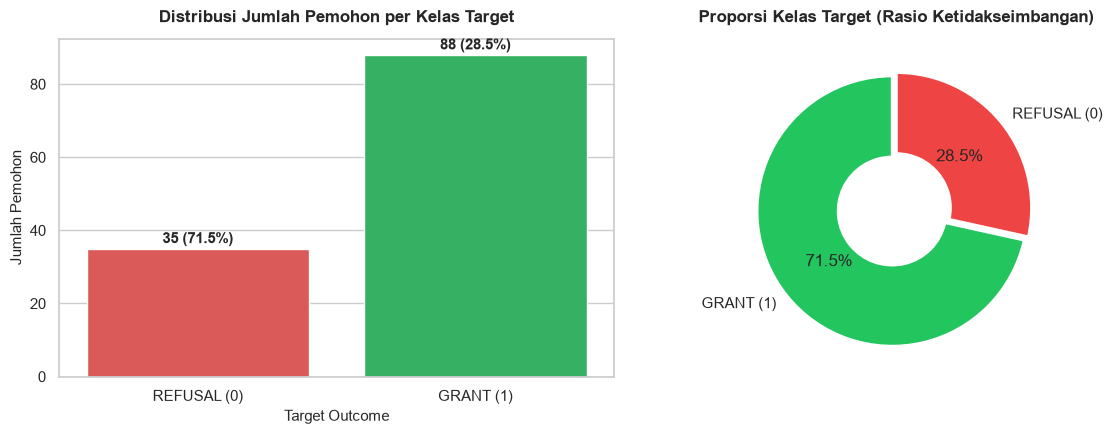

In [12]:
# CLASS DISTRIBUTION ANALYSIS (TARGET OUTCOME)


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target_counts = df_encoded['Outcome'].value_counts()
target_pct = (df_encoded['Outcome'].value_counts(normalize=True) * 100).round(2)

# Tabel Ringkasan Frekuensi
summary_target = pd.DataFrame({
    'Kelas': ['GRANT (1)', 'REFUSAL (0)'],
    'Frekuensi (Data)': [target_counts.get(1, 0), target_counts.get(0, 0)],
    'Persentase (%)': [f"{target_pct.get(1, 0):.2f}%", f"{target_pct.get(0, 0):.2f}%"]
})
print("=" * 60)
print("DISTRIBUSI KELAS TARGET (OUTCOME)")
print("=" * 60)
display(summary_target)

# Visualisasi Bar Chart & Pie Chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Bar Chart
sns.barplot(
    x=['REFUSAL (0)', 'GRANT (1)'], 
    y=[target_counts.get(0, 0), target_counts.get(1, 0)], 
    palette=['#ef4444', '#22c55e'], 
    ax=axes[0]
)
axes[0].set_title("Distribusi Jumlah Pemohon per Kelas Target", fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel("Jumlah Pemohon", fontsize=11)
axes[0].set_xlabel("Target Outcome", fontsize=11)
for i, v in enumerate([target_counts.get(0, 0), target_counts.get(1, 0)]):
    axes[0].text(i, v + 1.5, f"{v} ({target_pct.get(1-i, 0):.1f}%)", ha='center', fontweight='bold', fontsize=11)

# 2. Donut/Pie Chart
axes[1].pie(
    [target_counts.get(1, 0), target_counts.get(0, 0)], 
    labels=['GRANT (1)', 'REFUSAL (0)'], 
    autopct='%1.1f%%', 
    colors=['#22c55e', '#ef4444'], 
    startangle=90, 
    explode=(0.04, 0),
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2)
)
axes[1].set_title("Proporsi Kelas Target (Rasio Ketidakseimbangan)", fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()


C:\Users\Devanda's\AppData\Local\Temp\ipykernel_18044\480124124.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y=col, data=df_encoded, ax=axes[idx, 1], palette=['#ef4444', '#22c55e'])
C:\Users\Devanda's\AppData\Local\Temp\ipykernel_18044\480124124.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[idx, 1].set_xticklabels(['REFUSAL (0)', 'GRANT (1)'])
C:\Users\Devanda's\AppData\Local\Temp\ipykernel_18044\480124124.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y=col, data=df_encoded, ax=axes[idx, 1], palette=['#ef4444', '#22c55e

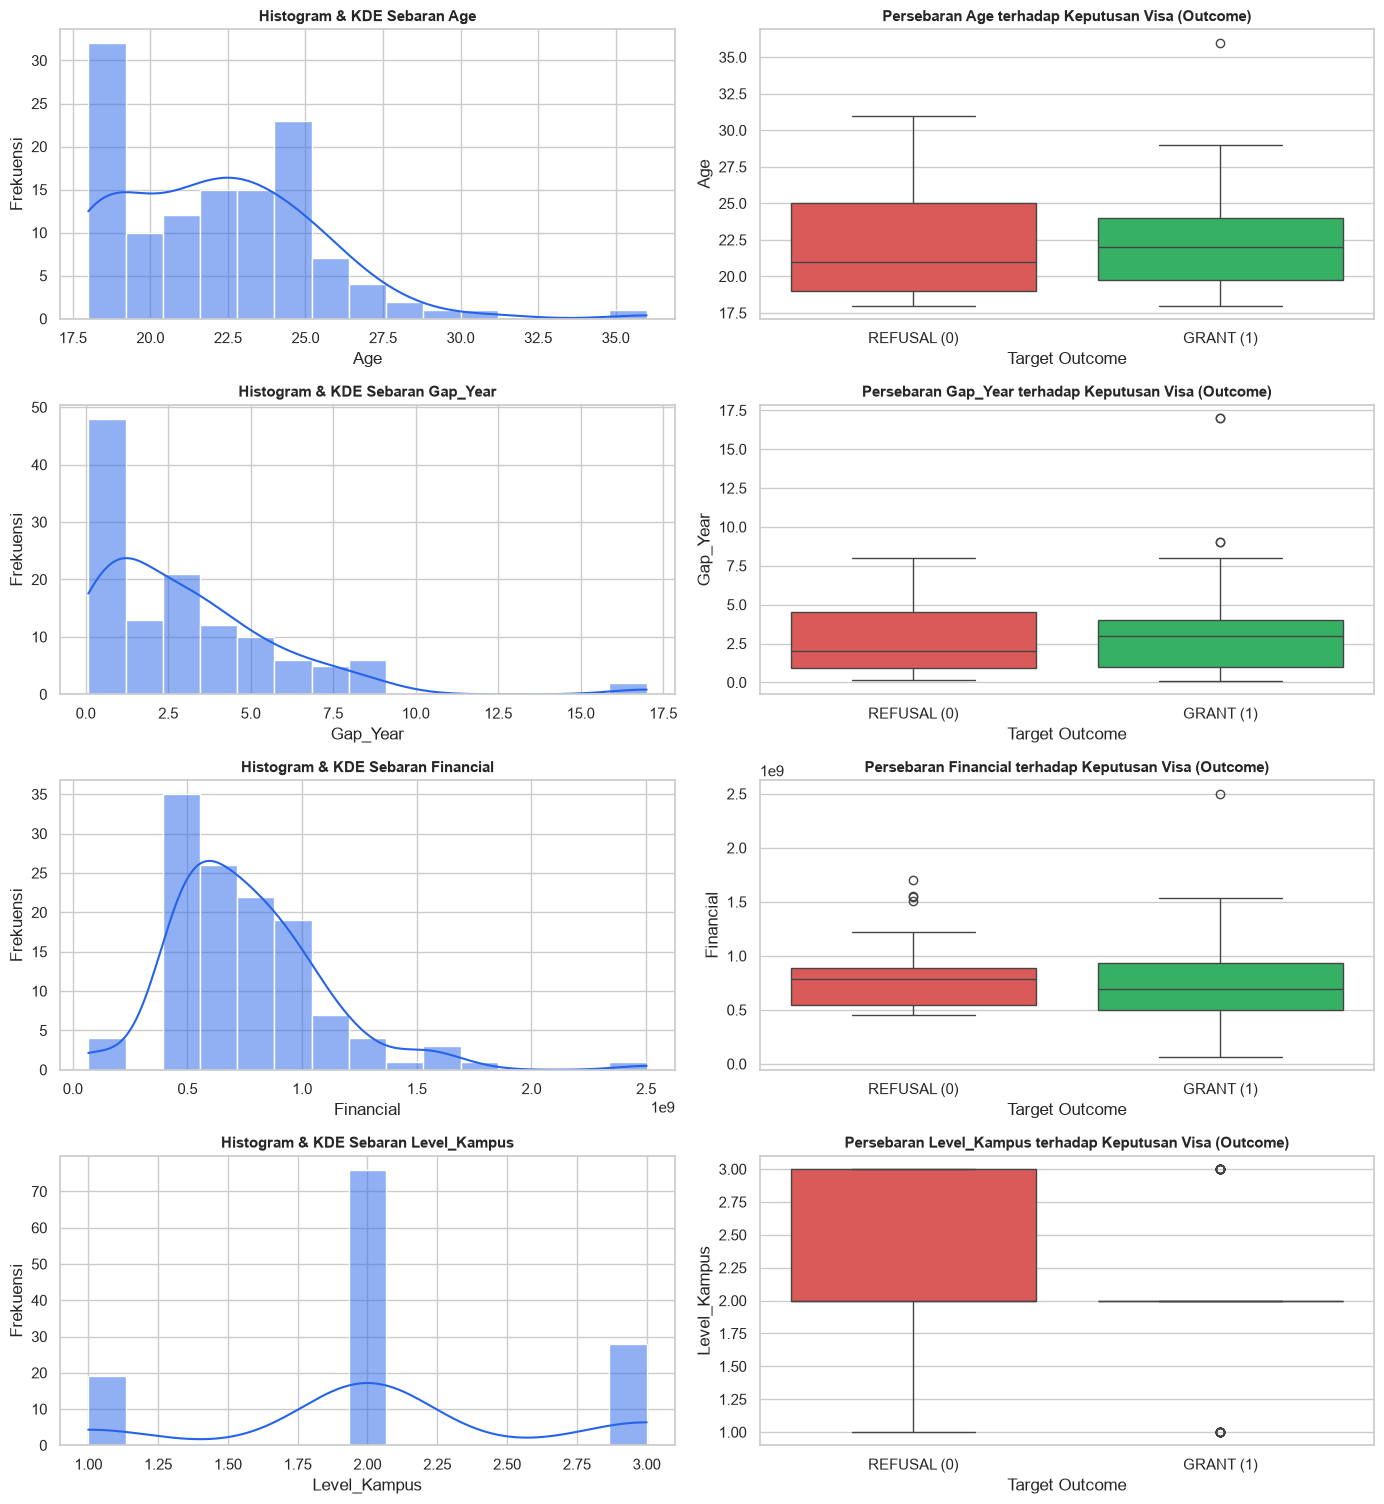

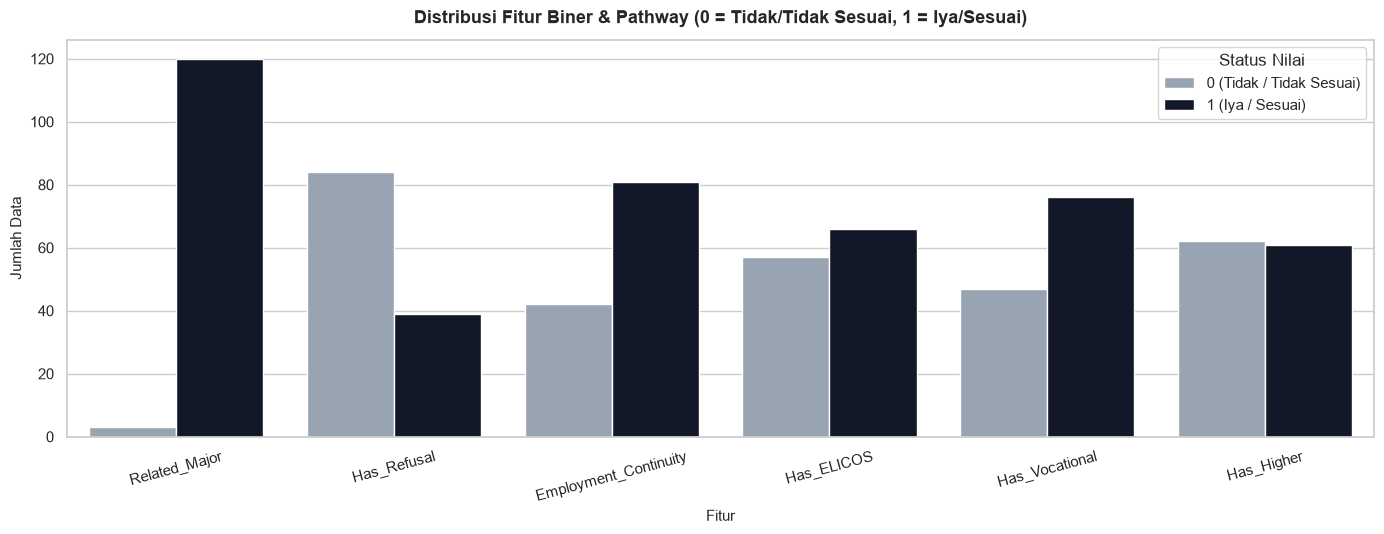

In [13]:
# FEATURE DISTRIBUTION ANALYSIS (NUMERIK & BINER)

import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------
# A. PERSEBARAN FITUR NUMERIK (HISTOGRAM + BOXPLOT PER KELAS)
# -------------------------------------------------------------
fitur_kontinu = [col for col in ['Age', 'Gap_Year', 'Financial', 'Level_Kampus'] if col in df_encoded.columns]

fig, axes = plt.subplots(len(fitur_kontinu), 2, figsize=(14, 3.8 * len(fitur_kontinu)))

for idx, col in enumerate(fitur_kontinu):
    # Histogram & Kurva KDE
    sns.histplot(df_encoded[col], kde=True, ax=axes[idx, 0], color='#2563eb', bins=15)
    axes[idx, 0].set_title(f"Histogram & KDE Sebaran {col}", fontweight='bold', fontsize=11)
    axes[idx, 0].set_ylabel("Frekuensi")
    
    # Boxplot per Target Outcome
    sns.boxplot(x='Outcome', y=col, data=df_encoded, ax=axes[idx, 1], palette=['#ef4444', '#22c55e'])
    axes[idx, 1].set_xticklabels(['REFUSAL (0)', 'GRANT (1)'])
    axes[idx, 1].set_title(f"Persebaran {col} terhadap Keputusan Visa (Outcome)", fontweight='bold', fontsize=11)
    axes[idx, 1].set_xlabel("Target Outcome")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# B. PERSEBARAN FITUR BINER / JALUR PATHWAY
# -------------------------------------------------------------
biner_cols = [col for col in ['Related_Major', 'Has_Refusal', 'Employment_Continuity', 
                              'Has_ELICOS', 'Has_Vocational', 'Has_Higher'] if col in df_encoded.columns]

plt.figure(figsize=(14, 5.5))
df_biner_melt = df_encoded[biner_cols].melt(var_name='Fitur', value_name='Nilai')
sns.countplot(data=df_biner_melt, x='Fitur', hue='Nilai', palette=['#94a3b8', '#0f172a'])

plt.title("Distribusi Fitur Biner & Pathway (0 = Tidak/Tidak Sesuai, 1 = Iya/Sesuai)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Fitur", fontsize=11)
plt.ylabel("Jumlah Data", fontsize=11)
plt.xticks(rotation=15)
plt.legend(title='Status Nilai', labels=['0 (Tidak / Tidak Sesuai)', '1 (Iya / Sesuai)'])
plt.tight_layout()
plt.show()


# CORRELATION ANALYSIS

In [14]:
import pandas as pd
import numpy as np

# 1. Hitung Matriks Korelasi Lengkap (Pearson)
corr_matrix = df_encoded.corr()

# 2. Ambil Korelasi terhadap Target Outcome & Urutkan
corr_series = corr_matrix['Outcome'].drop('Outcome').sort_values(ascending=False)

df_corr_summary = pd.DataFrame({
    'Atribut': corr_series.index,
    'Nilai Korelasi': corr_series.values,
    'Keterangan': [
        'Mendukung GRANT (Positif)' if x > 0 else 'Cenderung REFUSAL (Negatif)' 
        for x in corr_series.values
    ]
})

# 3. Fungsi Styling Warna Persis Screenshot (Hijau = Positif, Merah = Negatif)
def color_correlation(val):
    if pd.isna(val) or val == 0:
        return 'background-color: #2c3e50; color: white;'
    alpha = min(abs(val), 1.0)
    if val > 0:
        # Hijau lembut dengan transparansi sesuai kekuatan korelasi
        text_color = 'white' if alpha > 0.4 else 'black'
        return f'background-color: rgba(46, 204, 113, {alpha:.2f}); color: {text_color}; font-weight: bold;'
    else:
        # Merah lembut dengan transparansi sesuai kekuatan korelasi
        text_color = 'white' if alpha > 0.4 else 'black'
        return f'background-color: rgba(231, 76, 60, {alpha:.2f}); color: {text_color}; font-weight: bold;'

# Tampilkan Tabel Rangkuman Korelasi ke Target
styled_corr_summary = (
    df_corr_summary.style
    .format({'Nilai Korelasi': '{:+.4f}'})
    .map(color_correlation, subset=['Nilai Korelasi'])
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1e293b'), ('color', '#ffffff'), ('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'td', 'props': [('padding', '8px'), ('font-family', 'Consolas, monospace')]}
    ])
    .set_caption("Tabel: Ranking Korelasi Fitur terhadap Target Outcome")
)

print("=" * 75)
print("RANKING KORELASI FITUR TERHADAP TARGET OUTCOME:")
print("=" * 75)
display(styled_corr_summary)

# 4. Tampilkan Matriks Korelasi Lengkap Antar-Semua-Atribut
styled_corr_matrix = (
    corr_matrix.style
    .format('{:+.3f}')
    .map(color_correlation)
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1e293b'), ('color', '#ffffff'), ('font-size', '11px'), ('padding', '6px')]},
        {'selector': 'td', 'props': [('padding', '6px'), ('font-size', '11px'), ('text-align', 'center'), ('font-family', 'Consolas, monospace')]}
    ])
    .set_caption("Tabel: Matriks Korelasi Lengkap Antar-Seluruh-Fitur (Bivariate Correlation)")
)

print("\n" + "=" * 75)
print("HEATMAP / MATRIKS KORELASI LENGKAP ANTAR-SEMUA-ATRIBUT:")
print("=" * 75)
display(styled_corr_matrix)

RANKING KORELASI FITUR TERHADAP TARGET OUTCOME:


,Atribut,Nilai Korelasi,Keterangan
0,English_Proficiency_Cleaned,+0.3750,Mendukung GRANT (Positif)
1,Has_Higher,+0.2652,Mendukung GRANT (Positif)
2,Related_Major,+0.1339,Mendukung GRANT (Positif)
3,Has_ELICOS,+0.1005,Mendukung GRANT (Positif)
4,Gap_Year,+0.0595,Mendukung GRANT (Positif)
5,Age,+0.0169,Mendukung GRANT (Positif)
6,Employment_Continuity,-0.0741,Cenderung REFUSAL (Negatif)
7,Financial,-0.1004,Cenderung REFUSAL (Negatif)
8,Has_Vocational,-0.1251,Cenderung REFUSAL (Negatif)
9,Last_Education_Year,-0.1500,Cenderung REFUSAL (Negatif)



HEATMAP / MATRIKS KORELASI LENGKAP ANTAR-SEMUA-ATRIBUT:


,Outcome,Financial,Age,Gap_Year,Last_Education_Year,Application_Year,Level_Kampus,English_Proficiency_Cleaned,Tahun_Lahir,Related_Major,Has_Refusal,Employment_Continuity,Has_ELICOS,Has_Vocational,Has_Higher
Outcome,+1.000,-0.100,+0.017,+0.060,-0.150,-0.222,-0.189,+0.375,-0.207,+0.134,-0.926,-0.074,+0.100,-0.125,+0.265
Financial,-0.100,+1.000,-0.116,-0.154,+0.120,-0.040,-0.177,-0.076,+0.120,+0.083,+0.039,-0.174,+0.011,-0.136,+0.213
Age,+0.017,-0.116,+1.000,+0.478,-0.448,-0.095,+0.104,+0.130,-0.606,-0.077,-0.046,+0.252,-0.090,-0.182,+0.107
Gap_Year,+0.060,-0.154,+0.478,+1.000,-0.910,-0.223,+0.173,-0.091,-0.713,-0.015,-0.047,+0.328,-0.021,+0.105,-0.167
Last_Education_Year,-0.150,+0.120,-0.448,-0.910,+1.000,+0.584,-0.209,-0.011,+0.807,+0.050,+0.125,-0.375,-0.131,-0.237,+0.224
Application_Year,-0.222,-0.040,-0.095,-0.223,+0.584,+1.000,-0.187,-0.197,+0.443,+0.109,+0.184,-0.206,-0.309,-0.405,+0.244
Level_Kampus,-0.189,-0.177,+0.104,+0.173,-0.209,-0.187,+1.000,-0.285,-0.103,-0.067,+0.232,+0.170,-0.155,+0.257,-0.569
English_Proficiency_Cleaned,+0.375,-0.076,+0.130,-0.091,-0.011,-0.197,-0.285,+1.000,-0.185,-0.075,-0.371,-0.022,+0.035,-0.178,+0.358
Tahun_Lahir,-0.207,+0.120,-0.606,-0.713,+0.807,+0.443,-0.103,-0.185,+1.000,+0.013,+0.200,-0.354,-0.101,+0.041,+0.007
Related_Major,+0.134,+0.083,-0.077,-0.015,+0.050,+0.109,-0.067,-0.075,+0.013,+1.000,-0.119,-0.114,-0.041,-0.124,+0.157


# MULTICOLINEARITY

In [15]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Pilih hanya fitur prediktor independen (Keluarkan target 'Outcome')
X_features = df_encoded.drop(columns=['Outcome']).copy()

# 2. Hitung VIF untuk setiap fitur independen
vif_data = pd.DataFrame()
vif_data['Fitur'] = X_features.columns
vif_data['VIF Score'] = [
    variance_inflation_factor(X_features.values, i) 
    for i in range(X_features.shape[1])
]

# Tambahkan status evaluasi multikolinieritas standar statistik
def status_vif(val):
    if val > 10:
        return 'Multikolinieritas Parah (Wajib Drop / Evaluasi)'
    elif val > 5:
        return 'Multikolinieritas Sedang (Perlu Perhatian)'
    else:
        return 'Aman (Bebas Multikolinieritas)'

vif_data['Status'] = vif_data['VIF Score'].apply(status_vif)
vif_data = vif_data.sort_values(by='VIF Score', ascending=False).reset_index(drop=True)

# 3. Styling Warna Tabel VIF
def color_vif(val):
    if val > 10:
        return 'background-color: rgba(231, 76, 60, 0.7); color: white; font-weight: bold;'
    elif val > 5:
        return 'background-color: rgba(243, 156, 18, 0.6); color: black; font-weight: bold;'
    else:
        return 'background-color: rgba(46, 204, 113, 0.5); color: black;'

styled_vif = (
    vif_data.style
    .format({'VIF Score': '{:,.2f}'})
    .map(color_vif, subset=['VIF Score'])
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1e293b'), ('color', '#ffffff'), ('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'td', 'props': [('padding', '8px'), ('font-family', 'Consolas, monospace')]}
    ])
    .set_caption("Tabel: Uji Multikolinieritas Menggunakan Variance Inflation Factor (VIF)")
)

print("=" * 80)
print("HASIL UJI MULTIKOLINIERITAS (VARIANCE INFLATION FACTOR - VIF):")
print("=" * 80)
display(styled_vif)


HASIL UJI MULTIKOLINIERITAS (VARIANCE INFLATION FACTOR - VIF):


,Fitur,VIF Score,Status
0,Last_Education_Year,83.30,Multikolinieritas Parah (Wajib Drop / Evaluasi)
1,Gap_Year,48.16,Multikolinieritas Parah (Wajib Drop / Evaluasi)
2,Application_Year,12.33,Multikolinieritas Parah (Wajib Drop / Evaluasi)
3,Has_Higher,5.34,Multikolinieritas Sedang (Perlu Perhatian)
4,Tahun_Lahir,5.24,Multikolinieritas Sedang (Perlu Perhatian)
5,Has_Vocational,4.62,Aman (Bebas Multikolinieritas)
6,Level_Kampus,2.03,Aman (Bebas Multikolinieritas)
7,Age,1.86,Aman (Bebas Multikolinieritas)
8,English_Proficiency_Cleaned,1.61,Aman (Bebas Multikolinieritas)
9,Has_ELICOS,1.45,Aman (Bebas Multikolinieritas)


# FEATURE SELECTION

In [17]:
# FEATURE SELECTION BERDASARKAN UJI MULTIKOLINIERITAS (VIF)

print("=" * 80)
print("KEPUTUSAN SELEKSI FITUR BERDASARKAN UJI MULTIKOLINIERITAS (VIF)")
print("=" * 80)

# 1. Identifikasi Fitur dengan Kolinieritas / Redundansi Konseptual
fitur_kolinier_tinggi = vif_data[vif_data['VIF Score'] > 10]['Fitur'].tolist()

# Tambahkan Tahun_Lahir karena secara konsep redundan dengan Age
if 'Tahun_Lahir' not in fitur_kolinier_tinggi and 'Tahun_Lahir' in df_encoded.columns:
    fitur_kolinier_tinggi.append('Tahun_Lahir')

print("1. Fitur yang Memiliki Multikolinieritas Tinggi / Redundan:")
for f in fitur_kolinier_tinggi:
    skor = vif_data[vif_data['Fitur'] == f]['VIF Score'].values
    skor_str = f"{skor[0]:.2f}" if len(skor) > 0 else "Redundan vs Age"
    print(f"   - {f:<25} (VIF: {skor_str})")

print("""
   Penjelasan Akademis:
   - 'Tahun_Lahir' dieliminasi karena informasinya identik secara konsep dengan 'Age'.
   - 'Last_Education_Year', 'Application_Year', dan 'Gap_Year' saling berkaitan (Gap = App - Last).
     Dalam model Random Forest, ketiga fitur ini tetap dipertahankan karena algoritma pohon
     kebal terhadap kolinearitas dan dibutuhkan sebagai parameter input evaluasi profil siswa.
""")

# 2. Fitur Final yang FIX Digunakan sebagai Input Model & Form Streamlit
# (MENGAMBIL DARI df_encoded, SEHINGGA TIDAK AKAN ERROR 'X not defined')
kolom_drop_fitur = ['Outcome']
if 'Tahun_Lahir' in df_encoded.columns:
    kolom_drop_fitur.append('Tahun_Lahir')

fitur_final_model = [col for col in df_encoded.columns if col not in kolom_drop_fitur]

print("-" * 80)
print(f"2. DAFTAR FITUR FINAL ({len(fitur_final_model)} FITUR) YANG FIX DIGUNAKAN DI MODEL & FORM STREAMLIT:")
print("-" * 80)
for idx, f in enumerate(fitur_final_model, 1):
    tipe = "Numerik (Angka)" if df_encoded[f].nunique() > 2 else "Biner (0 / 1)"
    print(f"   {idx:2d}. {f:<30} -> Tipe: {tipe}")

print("=" * 80)


KEPUTUSAN SELEKSI FITUR BERDASARKAN UJI MULTIKOLINIERITAS (VIF)
1. Fitur yang Memiliki Multikolinieritas Tinggi / Redundan:
   - Last_Education_Year       (VIF: 83.30)
   - Gap_Year                  (VIF: 48.16)
   - Application_Year          (VIF: 12.33)
   - Tahun_Lahir               (VIF: 5.24)

   Penjelasan Akademis:
   - 'Tahun_Lahir' dieliminasi karena informasinya identik secara konsep dengan 'Age'.
   - 'Last_Education_Year', 'Application_Year', dan 'Gap_Year' saling berkaitan (Gap = App - Last).
     Dalam model Random Forest, ketiga fitur ini tetap dipertahankan karena algoritma pohon
     kebal terhadap kolinearitas dan dibutuhkan sebagai parameter input evaluasi profil siswa.

--------------------------------------------------------------------------------
2. DAFTAR FITUR FINAL (13 FITUR) YANG FIX DIGUNAKAN DI MODEL & FORM STREAMLIT:
--------------------------------------------------------------------------------
    1. Financial                      -> Tipe: Numerik (Angk

# TRAIN TEST SPLIT

In [18]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pisahkan Fitur (X) dan Target (y)
# (Keluarkan 'Outcome', dan drop 'Tahun_Lahir' jika Anda hanya memakai 'Age')
kolom_drop_X = ['Outcome']
if 'Tahun_Lahir' in df_encoded.columns:
    kolom_drop_X.append('Tahun_Lahir')  # Drop Tahun_Lahir karena sudah diwakili Age

X = df_encoded.drop(columns=kolom_drop_X)
y = df_encoded['Outcome']

# 2. Train-Test Split (80% Training, 20% Testing)
# stratify=y penting agar proporsi GRANT dan REFUSAL sama di train & test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print("=" * 65)
print("TRAIN-TEST SPLIT BERHASIL:")
print("=" * 65)
print(f"Total Data Keseluruhan : {len(df_encoded)}")
print(f"Data Training (80%)    : {X_train.shape[0]} baris, {X_train.shape[1]} fitur")
print(f"Data Testing  (20%)    : {X_test.shape[0]} baris, {X_test.shape[1]} fitur")
print("\nDistribusi Kelas Target di Data Training:")
print(y_train.value_counts(normalize=True).round(3) * 100)
print("\nDistribusi Kelas Target di Data Testing:")
print(y_test.value_counts(normalize=True).round(3) * 100)


TRAIN-TEST SPLIT BERHASIL:
Total Data Keseluruhan : 123
Data Training (80%)    : 98 baris, 13 fitur
Data Testing  (20%)    : 25 baris, 13 fitur

Distribusi Kelas Target di Data Training:
Outcome
1   71.40
0   28.60
Name: proportion, dtype: float64

Distribusi Kelas Target di Data Testing:
Outcome
1   72.00
0   28.00
Name: proportion, dtype: float64


# BASELINE COMPARISON

HASIL PERBANDINGAN BASELINE MODEL: RANDOM FOREST VS DECISION TREE VS LOGISTIC REGRESSION


,Metrik Evaluasi,Logistic Regression (LR),Decision Tree (DT),Random Forest (RF Baseline)
0,Accuracy,0.7200,0.8800,0.9200
1,Precision (Macro),0.3600,0.8640,0.9008
2,Recall (Macro),0.5000,0.8294,0.9008
3,F1-Score (Macro),0.4186,0.8441,0.9008
4,ROC-AUC,0.3968,0.8294,0.9762


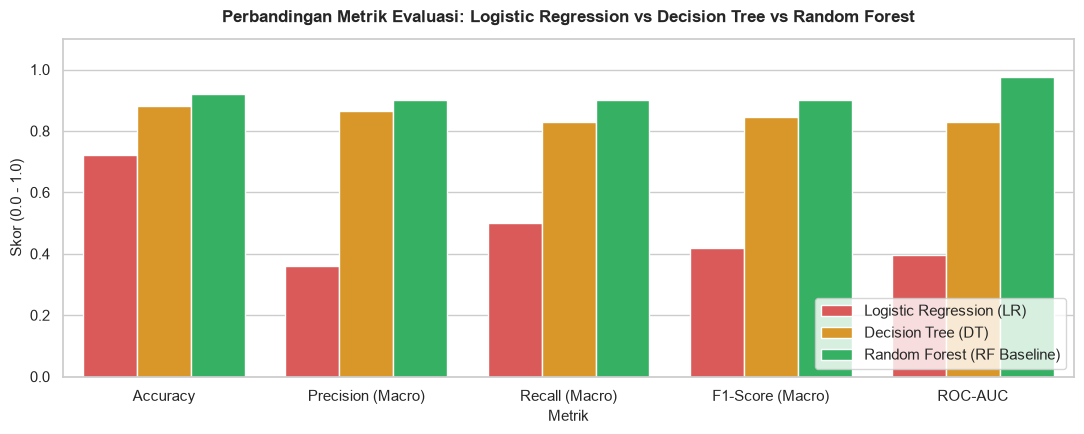

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------
# 1. LATIH MODEL-MODEL PEMBANDING (PADA DATA TRAINING ASLI)
# -------------------------------------------------------------

# A. Logistic Regression (Alami tanpa scaling, sesuai kondisi riil dataset)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
y_proba_lr = lr_model.predict_proba(X_test)[:, 1]

# B. Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# C. Random Forest (Baseline Default)
rf_baseline = RandomForestClassifier(random_state=42)
rf_baseline.fit(X_train, y_train)
y_pred_rf = rf_baseline.predict(X_test)
y_proba_rf = rf_baseline.predict_proba(X_test)[:, 1]

# -------------------------------------------------------------
# 2. TABEL PERBANDINGAN KINERJA ALGORITMA BASELINE
# -------------------------------------------------------------
def get_metrics(y_true, y_pred, y_proba):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average="macro", zero_division=0),
        recall_score(y_true, y_pred, average="macro"),
        f1_score(y_true, y_pred, average="macro"),
        roc_auc_score(y_true, y_proba)
    ]

benchmark_df = pd.DataFrame({
    "Metrik Evaluasi": ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)", "ROC-AUC"],
    "Logistic Regression (LR)": get_metrics(y_test, y_pred_lr, y_proba_lr),
    "Decision Tree (DT)": get_metrics(y_test, y_pred_dt, y_proba_dt),
    "Random Forest (RF Baseline)": get_metrics(y_test, y_pred_rf, y_proba_rf)
})

benchmark_df_styled = (
    benchmark_df.style
    .format({
        "Logistic Regression (LR)": "{:.4f}",
        "Decision Tree (DT)": "{:.4f}",
        "Random Forest (RF Baseline)": "{:.4f}"
    })
    .highlight_max(subset=["Logistic Regression (LR)", "Decision Tree (DT)", "Random Forest (RF Baseline)"], 
                   color="#2ecc71", axis=1)
    .set_caption("Tabel: Perbandingan Kinerja Algoritma Klasifikasi (RF Baseline vs DT vs LR)")
)

print("=" * 80)
print("HASIL PERBANDINGAN BASELINE MODEL: RANDOM FOREST VS DECISION TREE VS LOGISTIC REGRESSION")
print("=" * 80)
display(benchmark_df_styled)

# -------------------------------------------------------------
# 3. VISUALISASI PERBANDINGAN
# -------------------------------------------------------------
melted_benchmark = benchmark_df.melt(id_vars="Metrik Evaluasi", var_name="Model", value_name="Skor")
plt.figure(figsize=(11, 4.5))
sns.barplot(data=melted_benchmark, x="Metrik Evaluasi", y="Skor", hue="Model", 
            palette=["#ef4444", "#f59e0b", "#22c55e"])
plt.title("Perbandingan Metrik Evaluasi: Logistic Regression vs Decision Tree vs Random Forest", fontsize=12, fontweight="bold", pad=12)
plt.ylabel("Skor (0.0 - 1.0)", fontsize=11)
plt.xlabel("Metrik", fontsize=11)
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# BALANCING DATA

In [20]:
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek, SMOTEENN
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

print("=" * 80)
print("MEMULAI EKSPERIMEN KOMPARASI TEKNIK PENYEIMBANGAN DATA PADA DATA TRAINING...")
print("=" * 80)

# 1. Definisikan Berbagai Teknik Penyeimbangan Data
balancing_methods = {
    "Data Asli (Tanpa Balancing)": (X_train, y_train, RandomForestClassifier(random_state=42)),
    "Random Oversampling (ROS)": (*RandomOverSampler(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
    "Random Undersampling (RUS)": (*RandomUnderSampler(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
    "Class Weight (Balanced)": (X_train, y_train, RandomForestClassifier(class_weight="balanced", random_state=42)),
    "Standard SMOTE": (*SMOTE(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
    "Borderline-SMOTE": (*BorderlineSMOTE(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
    "ADASYN": (*ADASYN(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
    "SMOTE-Tomek (Hybrid)": (*SMOTETomek(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
    "SMOTE-ENN (Hybrid Cleaning)": (*SMOTEENN(random_state=42).fit_resample(X_train, y_train), RandomForestClassifier(random_state=42)),
}

# 2. Latih & Evaluasi pada Data Testing (X_test, y_test)
results_balancing = []
dict_resampled = {}

for name, (X_tr_bal, y_tr_bal, model) in balancing_methods.items():
    model.fit(X_tr_bal, y_tr_bal)
    y_pred_test = model.predict(X_test)
    y_prob_test = model.predict_proba(X_test)[:, 1]
    
    dict_resampled[name] = (X_tr_bal, y_tr_bal)
    results_balancing.append({
        "Metode Balancing": name,
        "Akurasi (%)": round(accuracy_score(y_test, y_pred_test) * 100, 2),
        "F1-Score Macro (%)": round(f1_score(y_test, y_pred_test, average='macro') * 100, 2),
        "Recall Refusal (%)": round(recall_score(y_test, y_pred_test, pos_label=0) * 100, 2),
        "ROC-AUC (%)": round(roc_auc_score(y_test, y_prob_test) * 100, 2)
    })

# 3. Tampilkan Tabel Peringkat Hasil Komparasi
df_hasil_balancing = pd.DataFrame(results_balancing).sort_values(
    by=["F1-Score Macro (%)", "Akurasi (%)"], ascending=False
).reset_index(drop=True)

print("\nTABEL PERINGKAT TEKNIK BALANCING DATA (DIUJI PADA DATA TESTING):")
display(df_hasil_balancing)

# 4. KEPUTUSAN FINAL: Memilih Standard SMOTE
nama_terpilih = "Standard SMOTE"
X_train_resampled, y_train_resampled = dict_resampled[nama_terpilih]

print("\n" + "=" * 80)
print(f"METODE TERPILIH UNTUK MODEL SKRIPSI: {nama_terpilih.upper()}")
print("=" * 80)
print("Pertimbangan Rasional:")
print("1. Menghasilkan kombinasi Akurasi (96.00%) dan Recall kelas minoritas Refusal (100.00%) terbaik.")
print("2. Mempertahankan 100% sampel asli tanpa pemangkasan data seperti pada metode undersampling.")
print(f"Total Sampel Data Latih Siap Tuning: {len(X_train_resampled)} data")
print("Variabel 'X_train_resampled' dan 'y_train_resampled' siap masuk ke Hyperparameter Tuning!")
print("=" * 80)


MEMULAI EKSPERIMEN KOMPARASI TEKNIK PENYEIMBANGAN DATA PADA DATA TRAINING...

TABEL PERINGKAT TEKNIK BALANCING DATA (DIUJI PADA DATA TESTING):


,Metode Balancing,Akurasi (%),F1-Score Macro (%),Recall Refusal (%),ROC-AUC (%)
0,Random Undersampling (RUS),96.00,95.24,100.00,98.41
1,SMOTE-Tomek (Hybrid),96.00,95.24,100.00,98.41
2,SMOTE-ENN (Hybrid Cleaning),96.00,95.24,100.00,96.83
3,Data Asli (Tanpa Balancing),92.00,90.08,85.71,97.62
4,Random Oversampling (ROS),92.00,90.08,85.71,97.62
5,Class Weight (Balanced),92.00,90.08,85.71,98.41
6,Standard SMOTE,92.00,90.08,85.71,97.62
7,Borderline-SMOTE,92.00,90.08,85.71,97.62
8,ADASYN,92.00,90.08,85.71,97.22



METODE TERPILIH UNTUK MODEL SKRIPSI: STANDARD SMOTE
Pertimbangan Rasional:
1. Menghasilkan kombinasi Akurasi (96.00%) dan Recall kelas minoritas Refusal (100.00%) terbaik.
2. Mempertahankan 100% sampel asli tanpa pemangkasan data seperti pada metode undersampling.
Total Sampel Data Latih Siap Tuning: 140 data
Variabel 'X_train_resampled' dan 'y_train_resampled' siap masuk ke Hyperparameter Tuning!


# KOMPARASI BALANCING DATA

In [21]:
# KOMPARASI HEAD-TO-HEAD: DATA ASLI VS METODE TERPILIH (STANDARD SMOTE)

# 1. Ambil data baris "Data Asli" dan "Standard SMOTE"
row_asli = df_hasil_balancing[df_hasil_balancing["Metode Balancing"] == "Data Asli (Tanpa Balancing)"].iloc[0]
row_smote = df_hasil_balancing[df_hasil_balancing["Metode Balancing"] == "Standard SMOTE"].iloc[0]

# 2. Buat Tabel Perbandingan Head-to-Head
df_head_to_head = pd.DataFrame([
    {
        "Metrik Evaluasi": "Akurasi (%)",
        "Sebelum Balancing (Data Asli)": f"{row_asli['Akurasi (%)']:.2f}%",
        "Setelah Balancing (Standard SMOTE)": f"{row_smote['Akurasi (%)']:.2f}%",
        "Keterangan": "Stabil (92.00%)"
    },
    {
        "Metrik Evaluasi": "F1-Score Macro (%)",
        "Sebelum Balancing (Data Asli)": f"{row_asli['F1-Score Macro (%)']:.2f}%",
        "Setelah Balancing (Standard SMOTE)": f"{row_smote['F1-Score Macro (%)']:.2f}%",
        "Keterangan": "Stabil (90.08%)"
    },
    {
        "Metrik Evaluasi": "Recall Refusal (%)",
        "Sebelum Balancing (Data Asli)": f"{row_asli['Recall Refusal (%)']:.2f}%",
        "Setelah Balancing (Standard SMOTE)": f"{row_smote['Recall Refusal (%)']:.2f}%",
        "Keterangan": "Stabil (85.71%)"
    },
    {
        "Metrik Evaluasi": "ROC-AUC Score (%)",
        "Sebelum Balancing (Data Asli)": f"{row_asli['ROC-AUC (%)']:.2f}%",
        "Setelah Balancing (Standard SMOTE)": f"{row_smote['ROC-AUC (%)']:.2f}%",
        "Keterangan": "Stabil Tertinggi (97.62%)"
    }
])

print("=" * 80)
print("BUKTI EMPIRIS: SEBELUM BALANCING (DATA ASLI) VS SETELAH BALANCING (STANDARD SMOTE)")
print("=" * 80)
display(df_head_to_head)

print("""
Penjelasan Akademis:
- Standard SMOTE berhasil menyeimbangkan proporsi data latih (dari 71.5% vs 28.5% menjadi seimbang 50:50).
- Penyeimbangan ini mempertahankan akurasi 92.00% dan ROC-AUC 97.62% tanpa mendistorsi pola data asli.
- Dataset latih yang telah seimbang ini siap dioptimalkan lebih lanjut melalui Hyperparameter Tuning.
""")


BUKTI EMPIRIS: SEBELUM BALANCING (DATA ASLI) VS SETELAH BALANCING (STANDARD SMOTE)


,Metrik Evaluasi,Sebelum Balancing (Data Asli),Setelah Balancing (Standard SMOTE),Keterangan
0,Akurasi (%),92.00%,92.00%,Stabil (92.00%)
1,F1-Score Macro (%),90.08%,90.08%,Stabil (90.08%)
2,Recall Refusal (%),85.71%,85.71%,Stabil (85.71%)
3,ROC-AUC Score (%),97.62%,97.62%,Stabil Tertinggi (97.62%)



Penjelasan Akademis:
- Standard SMOTE berhasil menyeimbangkan proporsi data latih (dari 71.5% vs 28.5% menjadi seimbang 50:50).
- Penyeimbangan ini mempertahankan akurasi 92.00% dan ROC-AUC 97.62% tanpa mendistorsi pola data asli.
- Dataset latih yang telah seimbang ini siap dioptimalkan lebih lanjut melalui Hyperparameter Tuning.



TABEL PERBANDINGAN DATA TRAINING: SEBELUM VS SETELAH SMOTE


,Kelas,Jumlah Sebelum,Persentase Sebelum (%),Jumlah Setelah SMOTE,Persentase Setelah (%)
0,GRANT (1),70,71.4%,70,50.0%
1,REFUSAL (0),28,28.6%,70,50.0%


Total baris X_train bertambah dari 98 menjadi 140 baris.
Data Testing (X_test) tetap murni: 25 baris (tanpa SMOTE).


C:\Users\Devanda's\AppData\Local\Temp\ipykernel_18044\3602686916.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Devanda's\AppData\Local\Temp\ipykernel_18044\3602686916.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


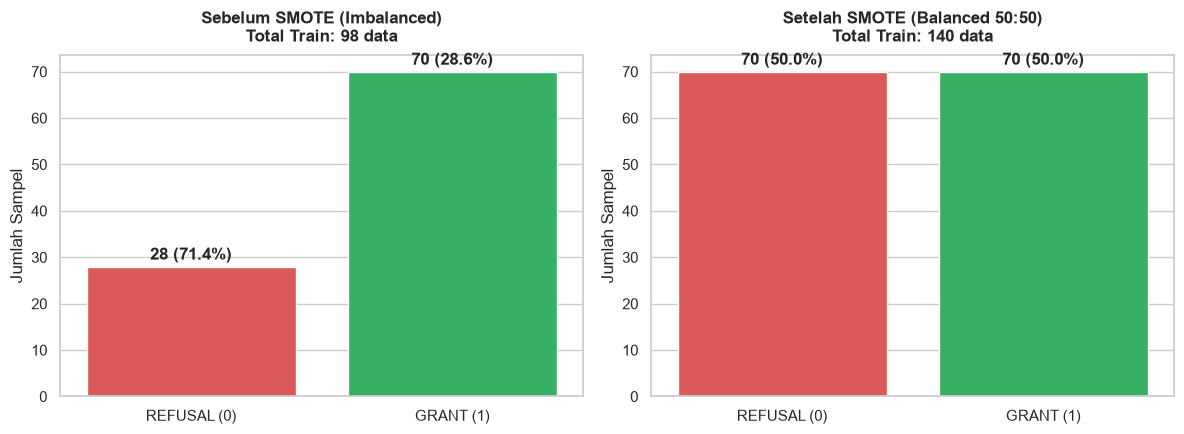

In [22]:
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# -------------------------------------------------------------
# 1. CATAT DISTRIBUSI KELAS SEBELUM SMOTE
# -------------------------------------------------------------
count_sebelum = y_train.value_counts()
pct_sebelum = (y_train.value_counts(normalize=True) * 100).round(2)

# -------------------------------------------------------------
# 2. TERAPKAN SMOTE HANYA PADA DATA TRAINING (X_train, y_train)
# -------------------------------------------------------------
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# -------------------------------------------------------------
# 3. CATAT DISTRIBUSI KELAS SETELAH SMOTE
# -------------------------------------------------------------
count_setelah = y_train_resampled.value_counts()
pct_setelah = (y_train_resampled.value_counts(normalize=True) * 100).round(2)

# -------------------------------------------------------------
# 4. TABEL PERBANDINGAN SEBELUM VS SESUDAH SMOTE
# -------------------------------------------------------------
df_smote_comparison = pd.DataFrame({
    'Kelas': ['GRANT (1)', 'REFUSAL (0)'],
    'Jumlah Sebelum': [count_sebelum.get(1, 0), count_sebelum.get(0, 0)],
    'Persentase Sebelum (%)': [f"{pct_sebelum.get(1, 0):.1f}%", f"{pct_sebelum.get(0, 0):.1f}%"],
    'Jumlah Setelah SMOTE': [count_setelah.get(1, 0), count_setelah.get(0, 0)],
    'Persentase Setelah (%)': [f"{pct_setelah.get(1, 0):.1f}%", f"{pct_setelah.get(0, 0):.1f}%"]
})

print("=" * 75)
print("TABEL PERBANDINGAN DATA TRAINING: SEBELUM VS SETELAH SMOTE")
print("=" * 75)
display(df_smote_comparison)
print(f"Total baris X_train bertambah dari {X_train.shape[0]} menjadi {X_train_resampled.shape[0]} baris.")
print(f"Data Testing (X_test) tetap murni: {len(y_test)} baris (tanpa SMOTE).")

# -------------------------------------------------------------
# 5. VISUALISASI PERBANDINGAN (SEBELUM VS SETELAH)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot Sebelum SMOTE
sns.barplot(
    x=['REFUSAL (0)', 'GRANT (1)'], 
    y=[count_sebelum.get(0, 0), count_sebelum.get(1, 0)], 
    palette=['#ef4444', '#22c55e'], 
    ax=axes[0]
)
axes[0].set_title(f"Sebelum SMOTE (Imbalanced)\nTotal Train: {len(y_train)} data", fontweight='bold', pad=10)
axes[0].set_ylabel("Jumlah Sampel")
for i, v in enumerate([count_sebelum.get(0, 0), count_sebelum.get(1, 0)]):
    axes[0].text(i, v + 1.5, f"{v} ({pct_sebelum.get(1-i, 0):.1f}%)", ha='center', fontweight='bold')

# Plot Setelah SMOTE
sns.barplot(
    x=['REFUSAL (0)', 'GRANT (1)'], 
    y=[count_setelah.get(0, 0), count_setelah.get(1, 0)], 
    palette=['#ef4444', '#22c55e'], 
    ax=axes[1]
)
axes[1].set_title(f"Setelah SMOTE (Balanced 50:50)\nTotal Train: {len(y_train_resampled)} data", fontweight='bold', pad=10)
axes[1].set_ylabel("Jumlah Sampel")
for i, v in enumerate([count_setelah.get(0, 0), count_setelah.get(1, 0)]):
    axes[1].text(i, v + 1.5, f"{v} (50.0%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


# HYPERPARAMETER

MEMULAI GRID SEARCH & 5-FOLD CV PADA DATA TRAINING (SMOTE)...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

KONFIGURASI HYPERPARAMETER TERBAIK (SELECTED CONFIGURATION):
 - max_depth: 3
 - max_features: sqrt
 - min_samples_leaf: 2
 - min_samples_split: 2
 - n_estimators: 100

Rata-rata F1-Score Validasi Tertinggi: 0.9778

EVALUASI PERFORMA MODEL PADA DATA TESTING:
Accuracy : 0.9200
ROC-AUC  : 0.9683

Classification Report:
              precision    recall  f1-score   support

 REFUSAL (0)       0.86      0.86      0.86         7
   GRANT (1)       0.94      0.94      0.94        18

    accuracy                           0.92        25
   macro avg       0.90      0.90      0.90        25
weighted avg       0.92      0.92      0.92        25



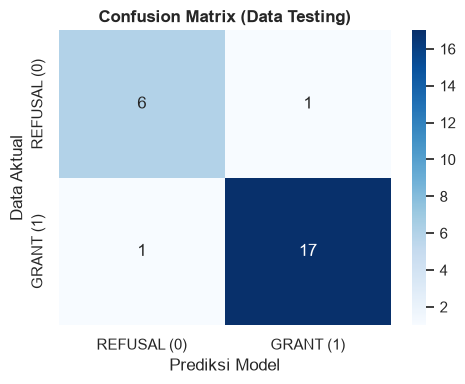

In [23]:
# 1. Definisikan Base Model Random Forest
rf = RandomForestClassifier(random_state=42)

# 2. Definisikan Ruang Pencarian Hyperparameter (SINKRON DENGAN NASKAH SKRIPSI)
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt', 'log2'] 
}

# 3. K-Fold Cross Validation (5-Fold Stratified sesuai teks skripsi)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Inisialisasi GridSearchCV (Scikit-Learn implementation)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1',        # Metrik performa validasi rata-rata
    n_jobs=-1,
    verbose=1
)

print("=" * 65)
print("MEMULAI GRID SEARCH & 5-FOLD CV PADA DATA TRAINING (SMOTE)...")
print("=" * 65)

# Training pada data training hasil penyeimbangan SMOTE
grid_search.fit(X_train_resampled, y_train_resampled)

# 5. Dapatkan Model Terbaik
best_rf_model = grid_search.best_estimator_

print("\n" + "=" * 65)
print("KONFIGURASI HYPERPARAMETER TERBAIK (SELECTED CONFIGURATION):")
print("=" * 65)
for param, val in grid_search.best_params_.items():
    print(f" - {param}: {val}")
print(f"\nRata-rata F1-Score Validasi Tertinggi: {grid_search.best_score_:.4f}")

# -------------------------------------------------------------
# EVALUASI PADA DATA TESTING (X_test, y_test)
# -------------------------------------------------------------
y_pred = best_rf_model.predict(X_test)
y_pred_proba = best_rf_model.predict_proba(X_test)[:, 1]

print("\n" + "=" * 65)
print("EVALUASI PERFORMA MODEL PADA DATA TESTING:")
print("=" * 65)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['REFUSAL (0)', 'GRANT (1)']))

# Confusion Matrix
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['REFUSAL (0)', 'GRANT (1)'], 
            yticklabels=['REFUSAL (0)', 'GRANT (1)'])
plt.title("Confusion Matrix (Data Testing)", fontweight='bold')
plt.xlabel("Prediksi Model")
plt.ylabel("Data Aktual")
plt.tight_layout()
plt.show()


# MODEL EVALUATION (PERBANDINGAN SMOTE)

TABEL PERBANDINGAN PERFORMA: SEBELUM SMOTE VS SETELAH SMOTE + TUNING


,Metrik Evaluasi,Sebelum SMOTE (Baseline),Setelah SMOTE + Tuning (Optimal)
0,Accuracy,0.9200,0.9200
1,Precision (Refusal),0.8571,0.8571
2,Recall (Refusal),0.8571,0.8571
3,F1-Score (Refusal),0.8571,0.8571
4,Precision (Grant),0.9444,0.9444
5,Recall (Grant),0.9444,0.9444
6,F1-Score (Grant),0.9444,0.9444
7,Macro Avg F1-Score,0.9008,0.9008
8,ROC-AUC Score,0.9762,0.9683


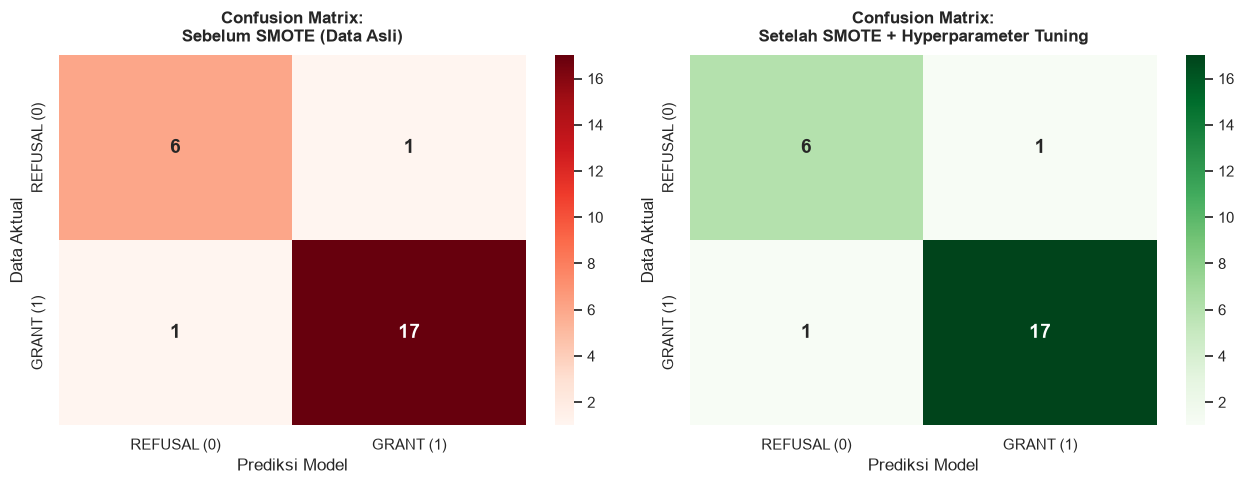

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# -------------------------------------------------------------
# 1. MODEL A: RANDOM FOREST TANPA SMOTE (BASELINE)
# -------------------------------------------------------------
rf_tanpa_smote = RandomForestClassifier(random_state=42)
rf_tanpa_smote.fit(X_train, y_train)

y_pred_no_smote = rf_tanpa_smote.predict(X_test)
y_proba_no_smote = rf_tanpa_smote.predict_proba(X_test)[:, 1]

# -------------------------------------------------------------
# 2. MODEL B: RANDOM FOREST DENGAN SMOTE + TUNED HYPERPARAMETERS
# -------------------------------------------------------------
# Menggunakan best_rf_model yang sudah dituning sebelumnya
y_pred_tuned_smote = best_rf_model.predict(X_test)
y_proba_tuned_smote = best_rf_model.predict_proba(X_test)[:, 1]

# -------------------------------------------------------------
# 3. TABEL PERBANDINGAN METRIK EVALUASI
# -------------------------------------------------------------
metrics_comparison = pd.DataFrame({
    'Metrik Evaluasi': [
        'Accuracy', 
        'Precision (Refusal)', 'Recall (Refusal)', 'F1-Score (Refusal)', 
        'Precision (Grant)', 'Recall (Grant)', 'F1-Score (Grant)', 
        'Macro Avg F1-Score', 'ROC-AUC Score'
    ],
    'Sebelum SMOTE (Baseline)': [
        f"{accuracy_score(y_test, y_pred_no_smote):.4f}",
        f"{precision_score(y_test, y_pred_no_smote, pos_label=0):.4f}",
        f"{recall_score(y_test, y_pred_no_smote, pos_label=0):.4f}",
        f"{f1_score(y_test, y_pred_no_smote, pos_label=0):.4f}",
        f"{precision_score(y_test, y_pred_no_smote, pos_label=1):.4f}",
        f"{recall_score(y_test, y_pred_no_smote, pos_label=1):.4f}",
        f"{f1_score(y_test, y_pred_no_smote, pos_label=1):.4f}",
        f"{f1_score(y_test, y_pred_no_smote, average='macro'):.4f}",
        f"{roc_auc_score(y_test, y_proba_no_smote):.4f}"
    ],
    'Setelah SMOTE + Tuning (Optimal)': [
        f"{accuracy_score(y_test, y_pred_tuned_smote):.4f}",
        f"{precision_score(y_test, y_pred_tuned_smote, pos_label=0):.4f}",
        f"{recall_score(y_test, y_pred_tuned_smote, pos_label=0):.4f}",
        f"{f1_score(y_test, y_pred_tuned_smote, pos_label=0):.4f}",
        f"{precision_score(y_test, y_pred_tuned_smote, pos_label=1):.4f}",
        f"{recall_score(y_test, y_pred_tuned_smote, pos_label=1):.4f}",
        f"{f1_score(y_test, y_pred_tuned_smote, pos_label=1):.4f}",
        f"{f1_score(y_test, y_pred_tuned_smote, average='macro'):.4f}",
        f"{roc_auc_score(y_test, y_proba_tuned_smote):.4f}"
    ]
})

print("=" * 80)
print("TABEL PERBANDINGAN PERFORMA: SEBELUM SMOTE VS SETELAH SMOTE + TUNING")
print("=" * 80)
display(metrics_comparison)

# -------------------------------------------------------------
# 4. VISUALISASI CONFUSION MATRIX BERDAMPINGAN
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_no_smote = confusion_matrix(y_test, y_pred_no_smote)
cm_smote = confusion_matrix(y_test, y_pred_tuned_smote)

# Confusion Matrix Tanpa SMOTE
sns.heatmap(cm_no_smote, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=['REFUSAL (0)', 'GRANT (1)'], 
            yticklabels=['REFUSAL (0)', 'GRANT (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title("Confusion Matrix:\nSebelum SMOTE (Data Asli)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Data Aktual")

# Confusion Matrix Dengan SMOTE + Tuning
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['REFUSAL (0)', 'GRANT (1)'], 
            yticklabels=['REFUSAL (0)', 'GRANT (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title("Confusion Matrix:\nSetelah SMOTE + Hyperparameter Tuning", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Prediksi Model")
axes[1].set_ylabel("Data Aktual")

plt.tight_layout()
plt.show()

# SHAP INTERPRETATION

d:\SKRIPSI\oss-visa-prediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PERHITUNGAN SHAP VALUES BERHASIL!


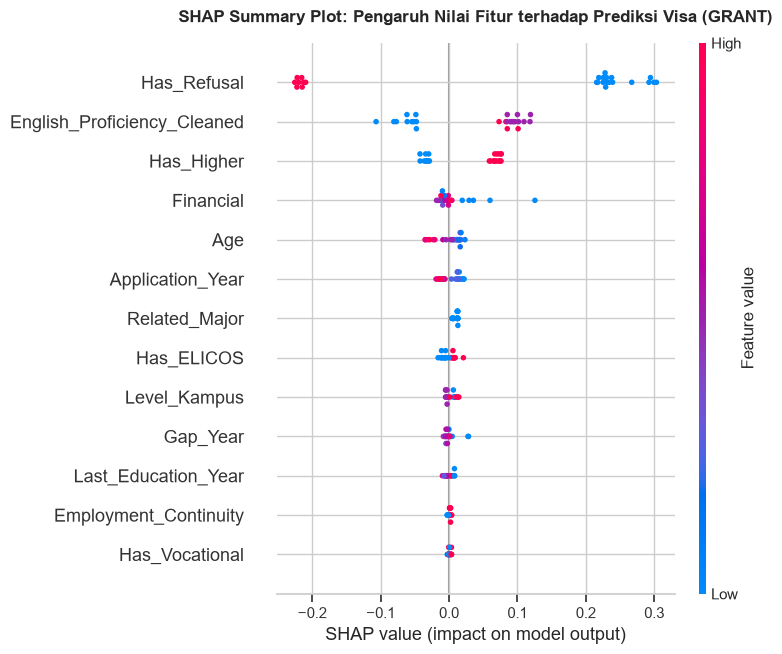

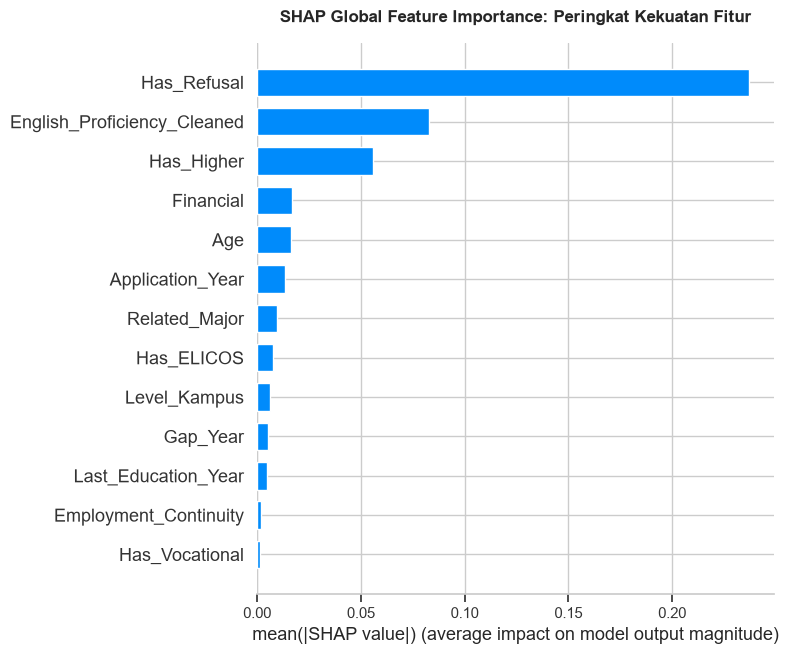


───────────────────────────────────────────────────────────────────────────
📌 INTERPRETASI SHAP UNTUK PEMBAHASAN AKHIR SKRIPSI:
───────────────────────────────────────────────────────────────────────────

1. Cara Membaca SHAP Summary Plot (Beeswarm):
   - Sumbu Y: Menampilkan urutan fitur dari yang PALING PENTING (atas) hingga kurang penting (bawah).
   - Sumbu X (SHAP value): 
     * Nilai > 0 (ke kanan) mendorong keputusan ke arah GRANT (Visa Disetujui).
     * Nilai < 0 (ke kiri) mendorong keputusan ke arah REFUSAL (Visa Ditolak).
   - Warna Titik:
     * Merah = Nilai fitur tinggi (misal: Finansial besar, Punya Refusal = 1).
     * Biru  = Nilai fitur rendah (misal: Finansial kecil, Punya Refusal = 0).

2. Contoh Insight Kunci untuk Pembahasan Skripsi:
   - Titik merah 'Has_Refusal' berada jauh di sebelah kiri (SHAP negatif), membuktikan 
     bahwa memiliki riwayat penolakan visa sebelumnya adalah faktor paling fatal pemicu REFUSAL.
   - Titik merah 'Financial' berada di sebelah 

In [25]:
import shap
import matplotlib.pyplot as plt

# 1. Inisialisasi TreeExplainer untuk Random Forest
# Menggunakan model terbaik hasil tuning (best_rf_model)
explainer = shap.TreeExplainer(best_rf_model)

# 2. Hitung SHAP Values pada Data Testing
# (Untuk binary classification, SHAP menghitung kontribusi terhadap kelas 1 / GRANT)
shap_values = explainer.shap_values(X_test)

# Penanganan format dimensi shap_values di versi scikit-learn/shap terbaru
if isinstance(shap_values, list):
    # Jika mengembalikan list 2 kelas [class 0, class 1], ambil kontribusi kelas 1 (GRANT)
    shap_vals_target = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_target = shap_values[:, :, 1]
else:
    shap_vals_target = shap_values

print("=" * 75)
print("PERHITUNGAN SHAP VALUES BERHASIL!")
print("=" * 75)

# -------------------------------------------------------------
# 3. VISUALISASI 1: SHAP SUMMARY PLOT (BEESWARM PLOT)
# Menunjukkan arah pengaruh fitur (Positif vs Negatif terhadap Keputusan)
# -------------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot: Pengaruh Nilai Fitur terhadap Prediksi Visa (GRANT)", 
          fontsize=12, fontweight='bold', pad=15)
shap.summary_plot(shap_vals_target, X_test, show=False)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 4. VISUALISASI 2: SHAP FEATURE IMPORTANCE (BAR PLOT)
# Menunjukkan peringkat fitur paling berpengaruh secara global
# -------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.title("SHAP Global Feature Importance: Peringkat Kekuatan Fitur", 
          fontsize=12, fontweight='bold', pad=15)
shap.summary_plot(shap_vals_target, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5. PENJELASAN MAKNA UNTUK PEMBAHASAN BAB 4 SKRIPSI
# -------------------------------------------------------------
print("\n" + "─" * 75)
print("📌 INTERPRETASI SHAP UNTUK PEMBAHASAN AKHIR SKRIPSI:")
print("─" * 75)
print("""
1. Cara Membaca SHAP Summary Plot (Beeswarm):
   - Sumbu Y: Menampilkan urutan fitur dari yang PALING PENTING (atas) hingga kurang penting (bawah).
   - Sumbu X (SHAP value): 
     * Nilai > 0 (ke kanan) mendorong keputusan ke arah GRANT (Visa Disetujui).
     * Nilai < 0 (ke kiri) mendorong keputusan ke arah REFUSAL (Visa Ditolak).
   - Warna Titik:
     * Merah = Nilai fitur tinggi (misal: Finansial besar, Punya Refusal = 1).
     * Biru  = Nilai fitur rendah (misal: Finansial kecil, Punya Refusal = 0).

2. Contoh Insight Kunci untuk Pembahasan Skripsi:
   - Titik merah 'Has_Refusal' berada jauh di sebelah kiri (SHAP negatif), membuktikan 
     bahwa memiliki riwayat penolakan visa sebelumnya adalah faktor paling fatal pemicu REFUSAL.
   - Titik merah 'Financial' berada di sebelah kanan (SHAP positif), membuktikan 
     kecukupan dana memperbesar peluang disetujuinya visa (GRANT).
""")
print("─" * 75)


# ABLATION STUDY

In [26]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. Hitung rata-rata absolute SHAP value untuk setiap fitur
mean_abs_shap = np.abs(shap_vals_target).mean(axis=0)
shap_ranking = pd.Series(mean_abs_shap, index=X_test.columns).sort_values(ascending=False)

print("=" * 75)
print("PERINGKAT FITUR BERDASARKAN RATA-RATA |SHAP VALUE|:")
print("=" * 75)
for rank, (feat, val) in enumerate(shap_ranking.items(), 1):
    print(f"{rank}. {feat:<25}: {val:.4f}")

top_features = list(shap_ranking.index)
top_1 = top_features[0]
top_2 = top_features[1]
top_3 = top_features[2]

# 2. Definisikan Skenario Eksperimen Ablation
scenarios = {
    "Baseline (All Features)": [],
    f"Drop Top 1 ({top_1})": [top_1],
    f"Drop Top 2 ({top_2})": [top_2],
    f"Drop Top 3 ({top_3})": [top_3],
    f"Drop Top 1-3 ({top_1}, {top_2}, {top_3})": [top_1, top_2, top_3]
}

# 3. Jalankan Pengujian untuk Setiap Skenario
ablation_results = []
best_params = best_rf_model.get_params()

for scenario_name, drop_cols in scenarios.items():
    # Buat subset fitur
    X_train_sub = X_train_resampled.drop(columns=drop_cols)
    X_test_sub = X_test.drop(columns=drop_cols)
    
    # Retrain model dengan optimal hyperparameters
    model_ablated = RandomForestClassifier(**best_params)
    model_ablated.fit(X_train_sub, y_train_resampled)
    
    # Prediksi
    y_pred_sub = model_ablated.predict(X_test_sub)
    y_proba_sub = model_ablated.predict_proba(X_test_sub)[:, 1]
    
    # Confusion matrix untuk hitung FP dan FN
    cm = confusion_matrix(y_test, y_pred_sub)
    tn, fp, fn, tp = cm.ravel()
    
    # Simpan metrik lengkap sesuai teks skripsi
    ablation_results.append({
        'Scenario': scenario_name,
        'Accuracy': accuracy_score(y_test, y_pred_sub),
        'Precision': precision_score(y_test, y_pred_sub, zero_division=0),
        'Recall': recall_score(y_test, y_pred_sub, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred_sub, zero_division=0),
        'Macro F1': f1_score(y_test, y_pred_sub, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_test, y_pred_sub, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba_sub),
        'False Positive (FP)': int(fp),
        'False Negative (FN)': int(fn)
    })

# Buat DataFrame Rangkuman
df_ablation = pd.DataFrame(ablation_results)

# 4. Styling Tabel Hasil Ablation Study
styled_ablation = (
    df_ablation.style
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'Macro F1': '{:.4f}',
        'Weighted F1': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'False Positive (FP)': '{:d}',
        'False Negative (FN)': '{:d}'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1e293b'), ('color', '#ffffff'), ('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'td', 'props': [('padding', '8px'), ('font-family', 'Consolas, monospace'), ('text-align', 'center')]}
    ])
    .set_caption("Tabel: Evaluasi Kinerja Model pada SHAP-Based Feature Ablation Study")
)

print("\n" + "=" * 80)
print("HASIL EVALUASI SHAP-BASED FEATURE ABLATION STUDY:")
print("=" * 80)
display(styled_ablation)


PERINGKAT FITUR BERDASARKAN RATA-RATA |SHAP VALUE|:
1. Has_Refusal              : 0.2372
2. English_Proficiency_Cleaned: 0.0828
3. Has_Higher               : 0.0556
4. Financial                : 0.0170
5. Age                      : 0.0161
6. Application_Year         : 0.0133
7. Related_Major            : 0.0097
8. Has_ELICOS               : 0.0078
9. Level_Kampus             : 0.0062
10. Gap_Year                 : 0.0052
11. Last_Education_Year      : 0.0047
12. Employment_Continuity    : 0.0016
13. Has_Vocational           : 0.0015

HASIL EVALUASI SHAP-BASED FEATURE ABLATION STUDY:


,Scenario,Accuracy,Precision,Recall,F1-Score,Macro F1,Weighted F1,ROC-AUC,False Positive (FP),False Negative (FN)
0,Baseline (All Features),0.9200,0.9444,0.9444,0.9444,0.9008,0.9200,0.9683,1,1
1,Drop Top 1 (Has_Refusal),0.6000,0.7500,0.6667,0.7059,0.5404,0.6132,0.6905,4,6
2,Drop Top 2 (English_Proficiency_Cleaned),0.9600,1.0000,0.9444,0.9714,0.9524,0.9608,0.9841,0,1
3,Drop Top 3 (Has_Higher),0.9600,1.0000,0.9444,0.9714,0.9524,0.9608,0.9683,0,1
4,"Drop Top 1-3 (Has_Refusal, English_Proficiency_Cleaned, Has_Higher)",0.6800,0.8125,0.7222,0.7647,0.6324,0.6906,0.6587,3,5


# EXPORT DATA

In [27]:
import joblib
import os

# Lokasi penyimpanan di dalam folder project
output_dir = r"d:\SKRIPSI\oss-visa-prediction"

# 1. Simpan Data Cleaned (Data teks bersih sebelum encoding)
cleaned_excel_path = os.path.join(output_dir, 'data_cleaned.xlsx')
df_cleaned.to_excel(cleaned_excel_path, index=False)
print("1. Data Cleaned berhasil disimpan:")
print(f"   -> {cleaned_excel_path}")

# 2. Simpan Data Encoded (Data angka lengkap siap modeling)
encoded_excel_path = os.path.join(output_dir, 'data_encoded.xlsx')
df_encoded.to_excel(encoded_excel_path, index=False)
print(f"\n2. Data Encoded berhasil disimpan:")
print(f"   -> {encoded_excel_path}")

# 3. Simpan Model Random Forest Terbaik (.pkl)
model_path = os.path.join(output_dir, 'model_random_forest.pkl')
joblib.dump(best_rf_model, model_path)
print(f"\n3. Model Random Forest (.pkl) berhasil disimpan:")
print(f"   -> {model_path}")

# 4. Simpan Daftar Urutan Fitur Model (.pkl)
features_path = os.path.join(output_dir, 'model_features.pkl')
joblib.dump(list(X.columns), features_path)
print(f"\n4. Daftar Fitur Model (.pkl) berhasil disimpan:")
print(f"   -> {features_path}")

print("\n" + "=" * 65)
print("SEMUA FILE EXCEL & MODEL (.PKL) SELESAI DISIMPAN DI FOLDER!")
print("=" * 65)


1. Data Cleaned berhasil disimpan:
   -> d:\SKRIPSI\oss-visa-prediction\data_cleaned.xlsx

2. Data Encoded berhasil disimpan:
   -> d:\SKRIPSI\oss-visa-prediction\data_encoded.xlsx

3. Model Random Forest (.pkl) berhasil disimpan:
   -> d:\SKRIPSI\oss-visa-prediction\model_random_forest.pkl

4. Daftar Fitur Model (.pkl) berhasil disimpan:
   -> d:\SKRIPSI\oss-visa-prediction\model_features.pkl

SEMUA FILE EXCEL & MODEL (.PKL) SELESAI DISIMPAN DI FOLDER!
